# Pantree: what the data says

This notebook explores the generated Pantree warehouse: sales over time, the February 2025 price change,
the shopping funnel, payments, returns, marketing channels and repeat customers. It ends with the
recommendation evaluation results.

Every number below is computed from the data when the notebook runs. The data is simulated (see the README),
so the findings describe how this shop behaves, not a real business.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()
DATA = ROOT / "data"
read = lambda name: pd.read_parquet(DATA / f"{name}.parquet")

# Chart style: one categorical palette in fixed order, thin marks, recessive grid.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.figsize": (9, 3.6), "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left",
    "lines.linewidth": 2, "font.size": 9,
})

from matplotlib.ticker import PercentFormatter

def hbar(series, title, fmt="{:.1%}", color=SERIES[0], sort=True):
    s = series.sort_values() if sort else series
    fig, ax = plt.subplots(figsize=(9, 0.38 * len(s) + 0.9))
    ax.barh(s.index.astype(str), s.values, color=color, height=0.62)
    for y, v in enumerate(s.values):
        ax.text(v, y, "  " + fmt.format(v), va="center", color=INK, fontsize=8.5)
    ax.set_title(title); ax.grid(axis="y", visible=False); ax.margins(x=0.12)
    if "%" in fmt:
        ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    plt.tight_layout(); plt.show()

tx = read("transactions"); tx["order_timestamp"] = pd.to_datetime(tx["order_timestamp"])
orders = read("orders"); orders["order_timestamp"] = pd.to_datetime(orders["order_timestamp"])
customers = read("customer_master"); products = read("product_master")
realized = orders[orders["is_realized"]]
SUMMARY = {}  # key numbers, written to analysis/insights_summary.json for the README

## 1. The dataset at a glance

In [2]:
sizes = {name: len(read(name)) for name in [
    "customer_master", "product_master", "orders", "transactions", "clickstream",
    "inventory", "returns", "product_reviews", "support_contacts"]}
print(pd.Series(sizes, name="rows").map("{:,}".format).to_string())
buyers = realized["customer_id"].nunique()
print(f"\nCustomers who bought at least once: {buyers:,} of {len(customers):,} ({buyers/len(customers):.1%})")
print(f"Realized revenue: ₹{realized['realized_revenue'].sum():,.0f} from {len(realized):,} paid orders")
print(f"Average order value: ₹{realized['realized_revenue'].mean():,.0f}")
SUMMARY.update(customers=len(customers), buyers=int(buyers), paid_orders=int(len(realized)),
               average_order_value=float(realized["realized_revenue"].mean()))

customer_master        33,060
product_master         10,000
orders                 31,370
transactions           49,890
clickstream         5,505,718
inventory           5,460,000
returns                 7,847
product_reviews        19,038
support_contacts        2,097

Customers who bought at least once: 11,510 of 33,060 (34.8%)
Realized revenue: ₹96,185,889 from 29,198 paid orders
Average order value: ₹3,294


## 2. Sales over time
Monthly realized revenue. Shaded months are festival and sale periods configured in the simulator.
Note the steady growth: new customers join every month, so later months are naturally larger.

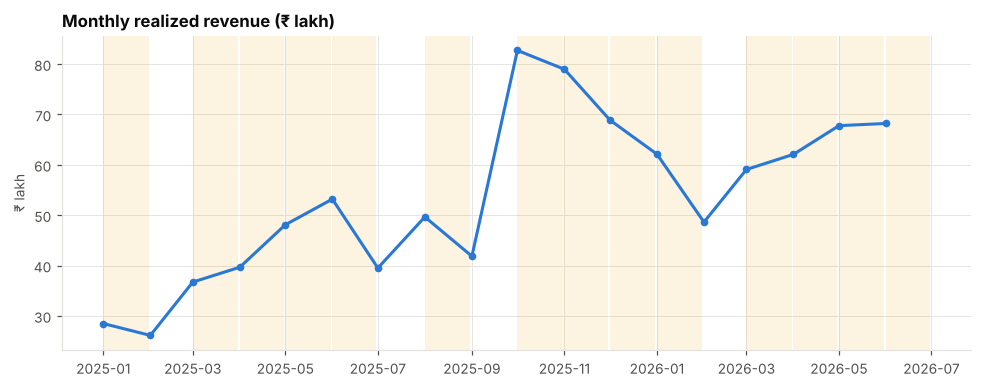

Best month: Oct 2025 (₹82.7 lakh); weakest: Feb 2025 (₹26.1 lakh)
Oct 2025 (Festive/Diwali): +83% vs neighbouring normal months
Nov 2025 (Festive/Diwali): +75% vs neighbouring normal months
Average festival-month uplift vs neighbouring normal months: +39%


In [3]:
monthly = realized.set_index("order_timestamp")["realized_revenue"].resample("MS").sum()
monthly = monthly.iloc[:-1] if monthly.index[-1].month == realized["order_timestamp"].max().month and realized["order_timestamp"].max().day < 25 else monthly
import sys; sys.path.insert(0, str(ROOT / "generators")); import config as C
fig, ax = plt.subplots()
for month in monthly.index:
    if C.festival_for(month.strftime("%Y-%m"))[0]:
        ax.axvspan(month, month + pd.offsets.MonthEnd(0), color="#eda100", alpha=0.12, lw=0)
ax.plot(monthly.index, monthly.values / 1e5, color=SERIES[0], marker="o", markersize=4)
ax.set_title("Monthly realized revenue (₹ lakh)"); ax.set_ylabel("₹ lakh")
plt.tight_layout(); plt.show()
best = monthly.idxmax()
print(f"Best month: {best:%b %Y} (₹{monthly.max()/1e5:.1f} lakh); weakest: {monthly.idxmin():%b %Y} (₹{monthly.min()/1e5:.1f} lakh)")
# The shop grows every month, so compare each festival month with the nearest
# non-festival months before and after it (a local baseline), not the overall average.
is_fest = [C.festival_for(m.strftime("%Y-%m"))[0] is not None for m in monthly.index]
uplifts = []
for i, month in enumerate(monthly.index):
    if not is_fest[i]:
        continue
    before = next((monthly.iloc[j] for j in range(i - 1, -1, -1) if not is_fest[j]), None)
    after = next((monthly.iloc[j] for j in range(i + 1, len(monthly)) if not is_fest[j]), None)
    neighbours = [v for v in (before, after) if v is not None]
    if neighbours:
        name = C.festival_for(month.strftime("%Y-%m"))[0]
        uplifts.append((month, name, monthly.iloc[i] / np.mean(neighbours) - 1))
for month, name, up in uplifts:
    if "Diwali" in name:
        print(f"{month:%b %Y} ({name}): {up:+.0%} vs neighbouring normal months")
print(f"Average festival-month uplift vs neighbouring normal months: {np.mean([u for *_, u in uplifts]):+.0%}")
SUMMARY["festival_uplift_avg"] = float(np.mean([u for *_, u in uplifts]))
SUMMARY["diwali_uplift"] = {f"{m:%b %Y}": float(u) for m, name, u in uplifts if "Diwali" in name}

## 3. The February 2025 price change
On 1 Feb 2025 prices rose 6–11%. Below: what shoppers paid relative to the listed price, and how many
orders each active customer placed per month.

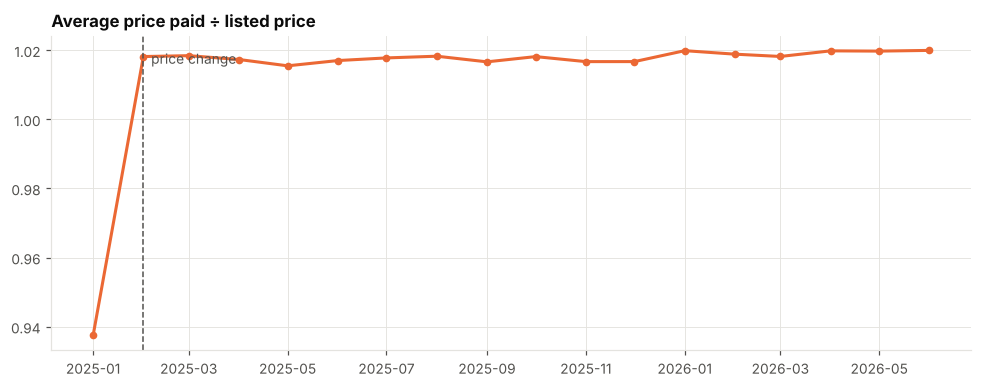

Paid/listed price: 0.937 before vs 1.018 after (+8.6%)


In [4]:
tx["paid_vs_list"] = tx["unit_selling_price"] / tx["listed_price"]
paid = tx[tx["net_item_value"] > 0].set_index("order_timestamp")["paid_vs_list"].resample("MS").mean()
fig, ax = plt.subplots()
ax.plot(paid.index, paid.values, color=SERIES[1], marker="o", markersize=4)
ax.axvline(pd.Timestamp(C.SHOCK_DATE), color=MUTED, lw=1, ls="--"); ax.text(pd.Timestamp(C.SHOCK_DATE), paid.max(), "  price change", color=MUTED, va="top")
ax.set_title("Average price paid ÷ listed price"); plt.tight_layout(); plt.show()
before = tx[(tx.order_timestamp < C.SHOCK_DATE) & (tx.net_item_value > 0)]["paid_vs_list"].mean()
after = tx[(tx.order_timestamp >= C.SHOCK_DATE) & (tx.net_item_value > 0)]["paid_vs_list"].mean()
print(f"Paid/listed price: {before:.3f} before vs {after:.3f} after ({after/before - 1:+.1%})")
SUMMARY["price_change_paid_vs_list"] = float(after / before - 1)

## 4. The shopping funnel

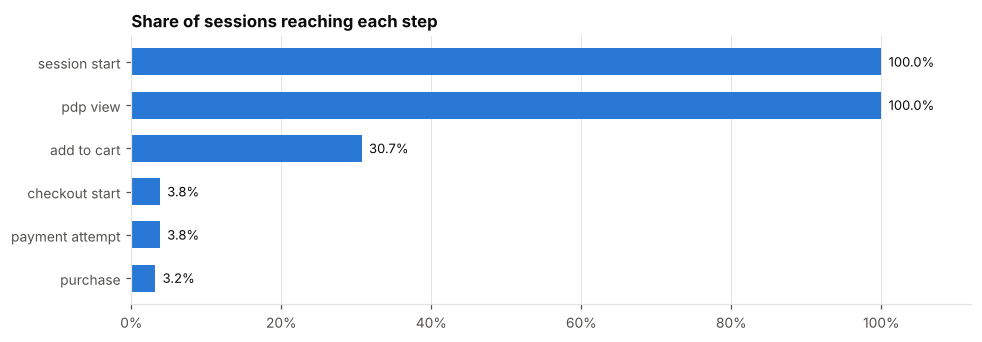

Sessions: 821,728; conversion to purchase: 3.20%
Cart → purchase: 10.4%


In [5]:
cs = read("clickstream")[["session_id", "event_type"]]
steps = ["session_start", "pdp_view", "add_to_cart", "checkout_start", "payment_attempt", "purchase"]
reached = {s: cs.loc[cs.event_type.eq(s), "session_id"].nunique() for s in steps}
total = reached["session_start"]
funnel = pd.Series({s.replace("_", " "): reached[s] / total for s in steps})
hbar(funnel.iloc[::-1], "Share of sessions reaching each step", sort=False)
print(f"Sessions: {total:,}; conversion to purchase: {reached['purchase']/total:.2%}")
print(f"Cart → purchase: {reached['purchase']/reached['add_to_cart']:.1%}")
SUMMARY.update(sessions=int(total), session_conversion=reached["purchase"] / total,
               cart_to_purchase=reached["purchase"] / reached["add_to_cart"])

## 5. Payments and delivery problems

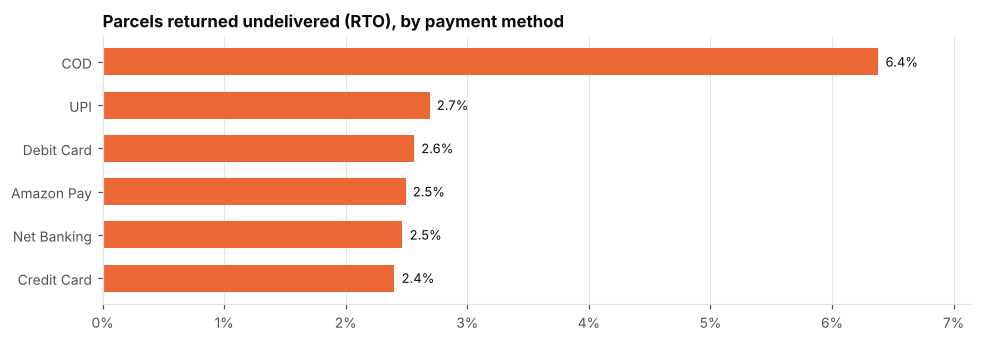

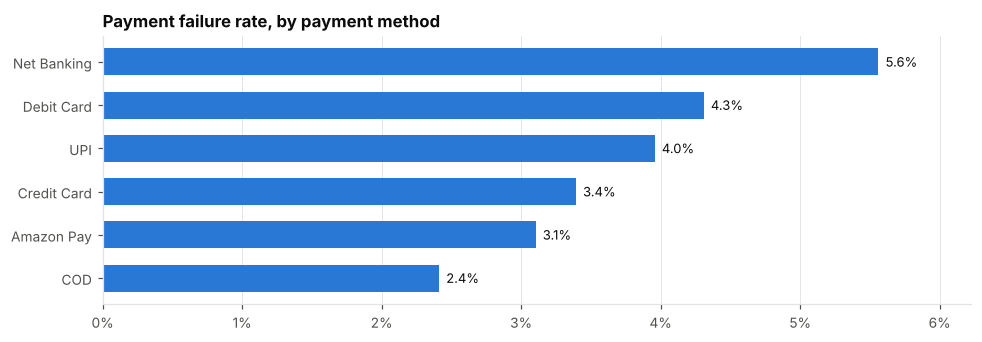

Cash on delivery RTO rate 6.4% vs 2.6% for prepaid (2.5×)


In [6]:
by_method = tx.groupby("payment_method").agg(
    failed=("payment_status", lambda s: s.eq("Failed").mean()),
    returned_to_origin=("order_status", lambda s: s.eq("RTO").mean()))
hbar(by_method["returned_to_origin"], "Parcels returned undelivered (RTO), by payment method", color=SERIES[1])
hbar(by_method["failed"], "Payment failure rate, by payment method", color=SERIES[0])
cod = by_method.loc["COD", "returned_to_origin"]; other = tx[tx.payment_method.ne("COD")]["order_status"].eq("RTO").mean()
print(f"Cash on delivery RTO rate {cod:.1%} vs {other:.1%} for prepaid ({cod/other:.1f}×)")
SUMMARY.update(cod_rto=float(cod), prepaid_rto=float(other))

## 6. Returns

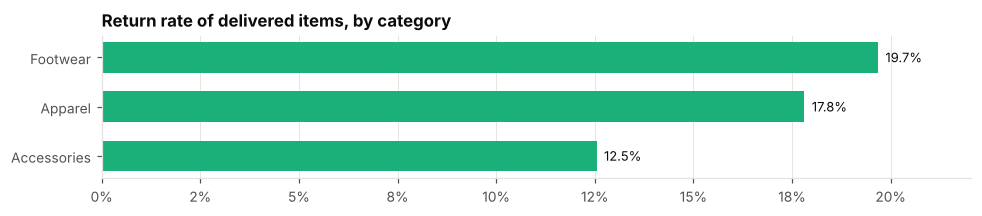

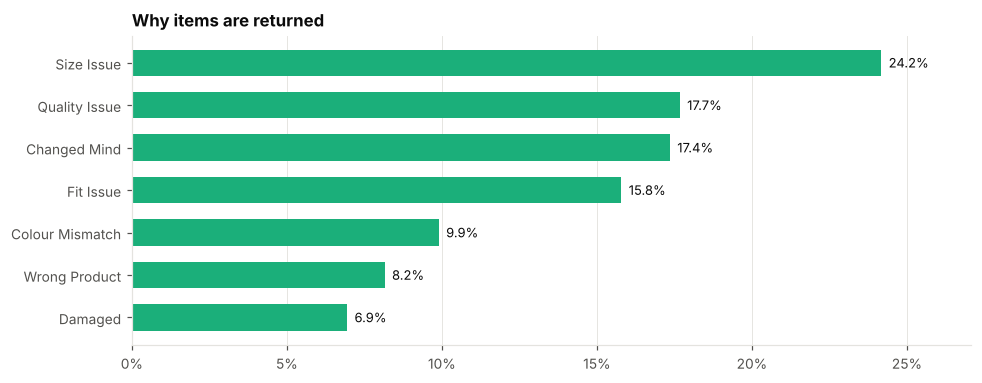

Overall return rate: 17.0%; top reason: Size Issue (24%)
Size + fit problems explain 40% of returns


In [7]:
ret = read("returns").merge(products[["product_id", "h1_category"]], on="product_id", how="left")
delivered = tx[tx.order_status.isin(["Delivered", "CIR"])].merge(products[["product_id", "h1_category"]], on="product_id")
rate = ret.groupby("h1_category").size() / delivered.groupby("h1_category").size()
hbar(rate.dropna(), "Return rate of delivered items, by category", color=SERIES[2])
reasons = ret["return_reason"].value_counts(normalize=True)
hbar(reasons, "Why items are returned", color=SERIES[2])
print(f"Overall return rate: {len(ret)/len(delivered):.1%}; top reason: {reasons.index[0]} ({reasons.iloc[0]:.0%})")
size_fit = reasons.reindex(['Size Issue', 'Fit Issue']).sum()
print(f"Size + fit problems explain {size_fit:.0%} of returns")
SUMMARY.update(return_rate=len(ret) / len(delivered), size_fit_share=float(size_fit),
               return_rate_by_category={k: float(v) for k, v in rate.dropna().items()})

## 7. Which marketing channels bring valuable customers?

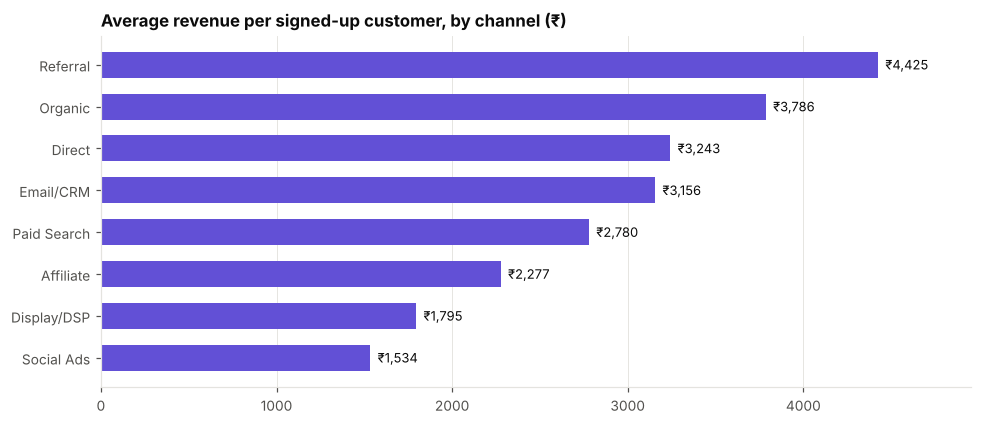

Best: Referral (₹4,425); weakest: Social Ads (₹1,534), a 2.9× gap


In [8]:
rev = realized.groupby("customer_id")["realized_revenue"].sum()
per_channel = customers.assign(revenue=customers.customer_id.map(rev).fillna(0)).groupby("acquisition_channel")["revenue"].mean()
hbar(per_channel, "Average revenue per signed-up customer, by channel (₹)", fmt="₹{:,.0f}", color=SERIES[6])
print(f"Best: {per_channel.idxmax()} (₹{per_channel.max():,.0f}); weakest: {per_channel.idxmin()} (₹{per_channel.min():,.0f}), "
      f"a {per_channel.max()/per_channel.min():.1f}× gap")
SUMMARY.update(best_channel=per_channel.idxmax(), best_channel_value=float(per_channel.max()),
               worst_channel=per_channel.idxmin(), worst_channel_value=float(per_channel.min()))

## 8. Repeat customers

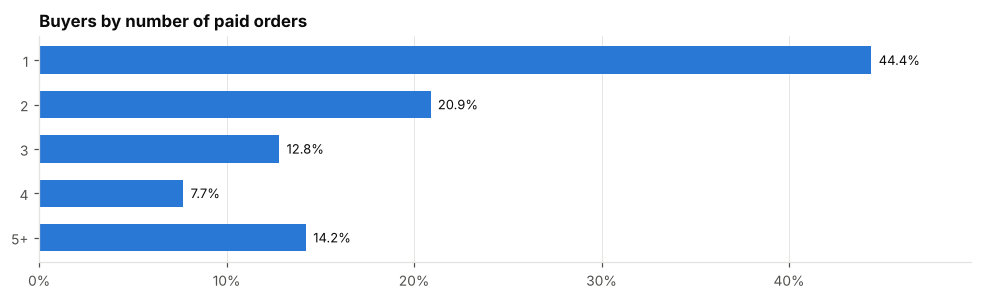

Repeat buyers: 55.6% of buyers, bringing 82.9% of revenue


In [9]:
orders_per_buyer = realized.groupby("customer_id").size()
repeat = orders_per_buyer[orders_per_buyer >= 2].index
share_repeat_rev = realized[realized.customer_id.isin(repeat)]["realized_revenue"].sum() / realized["realized_revenue"].sum()
dist = orders_per_buyer.clip(upper=5).value_counts(normalize=True).sort_index()
dist.index = [f"{i}" if i < 5 else "5+" for i in dist.index]
hbar(dist.iloc[::-1], "Buyers by number of paid orders", color=SERIES[0], sort=False)
print(f"Repeat buyers: {len(repeat)/len(orders_per_buyer):.1%} of buyers, bringing {share_repeat_rev:.1%} of revenue")
SUMMARY.update(repeat_buyer_share=len(repeat) / len(orders_per_buyer), repeat_revenue_share=float(share_repeat_rev))

## 9. Customer lifecycle and churn

Churn (no purchase in next 90 days) among recently active customers: 56.8% of 47,672 snapshots


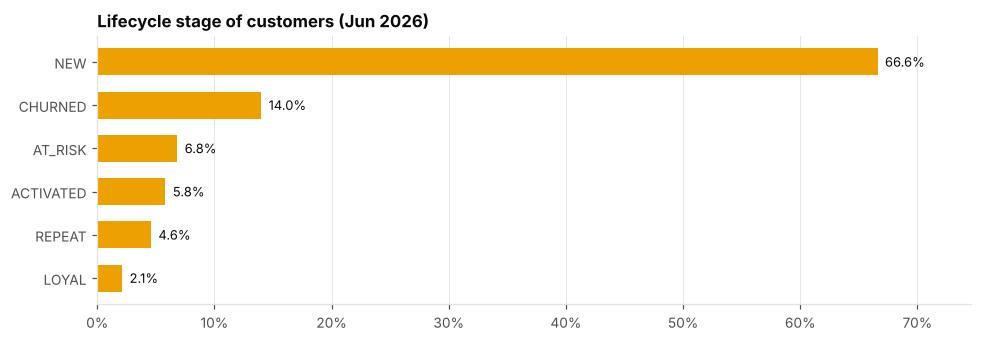

In [10]:
labels = read("customer_churn_labels")
features = read("customer_monthly_features")
print(f"Churn (no purchase in next 90 days) among recently active customers: {labels.churn_90d.mean():.1%} of {len(labels):,} snapshots")
latest = features[features.snapshot_date.eq(features.snapshot_date.max())]["lifecycle_state"].value_counts(normalize=True)
hbar(latest, f"Lifecycle stage of customers ({features.snapshot_date.max():%b %Y})", color=SERIES[3])

## 10. Churn: who stops buying?

**Label:** `churn_90d` = no realized purchase in the 90 days after `snapshot_date` (monthly snapshots). Only labels
whose 90-day window ends inside the data are kept (`label_observed`; the generator stores only those rows).
**Cohort:** customers with a realized purchase in the 90 days before the snapshot.
**Business use:** each month, send a retention offer to the 10% of active customers most likely to churn.

The generator also stores ready-made monthly features (`customer_monthly_features`). An earlier version counted orders
from the **whole snapshot month**, up to 30 days *after* `snapshot_date`, which overlapped the label window (leakage).
That is fixed in `generators/finalize_dataset.py`, `validators/validate_dataset.py` now fails if it comes back, and the
check below asserts it. Features are still rebuilt here from the raw tables, strictly before each snapshot.

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, f1_score
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

labels = read("customer_churn_labels")[["customer_id", "snapshot_date", "label_window_end", "churn_90d"]]
labels["snapshot_date"] = pd.to_datetime(labels["snapshot_date"])
labels["label_window_end"] = pd.to_datetime(labels["label_window_end"])
data_end = realized["order_timestamp"].max().normalize() + pd.Timedelta(days=1)
assert (labels["label_window_end"] > labels["snapshot_date"]).all(), "label window must start after the snapshot"
assert (labels["label_window_end"] <= data_end).all(), "only fully observed label windows"

# Leakage probe on the stored feature table: orders counted vs orders strictly before snapshot_date.
stored = read("customer_monthly_features")
stored["snapshot_date"] = pd.to_datetime(stored["snapshot_date"])
leaky_rows = 0
for snap, part in stored.groupby("snapshot_date"):
    strict = realized[realized["order_timestamp"] < snap].groupby("customer_id")["order_id"].nunique()
    leaky_rows += int((part.set_index("customer_id")["orders"] > strict.reindex(part["customer_id"]).fillna(0).to_numpy()).sum())
print(f"Stored feature rows counting orders on or after snapshot_date: {leaky_rows:,} of {len(stored):,}")
assert leaky_rows == 0, "stored features leak into the label window; see validators/validate_dataset.py"
SUMMARY["churn_stored_feature_leaky_rows"] = leaky_rows

Stored feature rows counting orders on or after snapshot_date: 0 of 534,480


In [12]:
returns_tbl = read("returns"); returns_tbl["return_requested_at"] = pd.to_datetime(returns_tbl["return_requested_at"])
support = read("support_contacts"); support["contact_timestamp"] = pd.to_datetime(support["contact_timestamp"])
signup = pd.to_datetime(customers.set_index("customer_id")["signup_date"])
prime = customers.set_index("customer_id")["is_prime_member"].astype(int)
FEATURES = ["recency_days", "tenure_days", "orders_total", "revenue_total", "avg_order_value",
            "orders_90d", "revenue_90d", "returns_90d", "support_contacts_90d", "negative_support_90d", "is_prime"]

def features_at(snapshot):
    # Point-in-time features: every source row is strictly before the snapshot date.
    hist = realized[realized["order_timestamp"] < snapshot]
    window = pd.Timedelta(days=90)
    recent = hist[hist["order_timestamp"] >= snapshot - window]
    rets = returns_tbl[(returns_tbl["return_requested_at"] < snapshot) & (returns_tbl["return_requested_at"] >= snapshot - window)]
    sup = support[(support["contact_timestamp"] < snapshot) & (support["contact_timestamp"] >= snapshot - window)]
    for source, col in ((hist, "order_timestamp"), (rets, "return_requested_at"), (sup, "contact_timestamp")):
        assert source.empty or source[col].max() < snapshot
    life = hist.groupby("customer_id").agg(orders_total=("order_id", "nunique"), revenue_total=("realized_revenue", "sum"),
                                           last_order=("order_timestamp", "max"))
    f = life.join(recent.groupby("customer_id").agg(orders_90d=("order_id", "nunique"), revenue_90d=("realized_revenue", "sum")))
    f = f.join(rets.groupby("customer_id").size().rename("returns_90d"))
    f = f.join(sup.groupby("customer_id").agg(support_contacts_90d=("contact_id", "size"),
                                              negative_support_90d=("customer_sentiment", lambda s: (s == "negative").sum())))
    f = f.fillna({c: 0 for c in ["orders_90d", "revenue_90d", "returns_90d", "support_contacts_90d", "negative_support_90d"]})
    f["recency_days"] = (snapshot - f["last_order"]).dt.days
    f["tenure_days"] = (snapshot - signup.reindex(f.index)).dt.days
    f["avg_order_value"] = f["revenue_total"] / f["orders_total"]
    f["is_prime"] = prime.reindex(f.index).fillna(0)
    return f.drop(columns=["last_order"]).assign(snapshot_date=snapshot).reset_index()

feats = pd.concat([features_at(s) for s in sorted(labels["snapshot_date"].unique())], ignore_index=True)
data = labels.merge(feats, on=["customer_id", "snapshot_date"], how="inner")
data = data[data["orders_90d"] >= 1].copy()        # cohort: bought in the 90 days before the snapshot
data["churn"] = data["churn_90d"].astype(int)
print(f"{len(data):,} customer-snapshots, {data['customer_id'].nunique():,} customers, churn rate {data['churn'].mean():.1%}")

47,672 customer-snapshots, 9,935 customers, churn rate 56.8%


In [13]:
# Temporal split with an embargo: a split's labels (snapshot + 90 days) must end before the next split starts.
snaps = sorted(data["snapshot_date"].unique())
test_snaps = snaps[-2:]
val_snaps = [s for s in snaps if s + pd.Timedelta(days=90) < test_snaps[0]][-2:]
train_snaps = [s for s in snaps if s + pd.Timedelta(days=90) < val_snaps[0]]
split = {"train": data[data["snapshot_date"].isin(train_snaps)], "validation": data[data["snapshot_date"].isin(val_snaps)],
         "test": data[data["snapshot_date"].isin(test_snaps)]}
assert split["train"]["label_window_end"].max() < split["validation"]["snapshot_date"].min()
assert split["validation"]["label_window_end"].max() < split["test"]["snapshot_date"].min()
for name, part in split.items():
    print(f"{name:10s} snapshots {part['snapshot_date'].min():%Y-%m}..{part['snapshot_date'].max():%Y-%m}  "
          f"rows {len(part):6,}  churn rate {part['churn'].mean():.1%}")
X = {k: v[FEATURES] for k, v in split.items()}
y = {k: v["churn"].to_numpy() for k, v in split.items()}

train      snapshots 2025-02..2025-07  rows 13,232  churn rate 58.6%
validation snapshots 2025-10..2025-11  rows  6,925  churn rate 51.7%
test       snapshots 2026-03..2026-04  rows  7,791  churn rate 56.4%


In [14]:
# (a) rule: churn risk = days since last order; threshold chosen on validation (best F1)
thresholds = np.arange(15, 91, 5)
best_t = max(thresholds, key=lambda t: f1_score(y["validation"], (X["validation"]["recency_days"] > t).astype(int)))
models = {
    "Recency rule": None,
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=0)),
    "Gradient boosting": HistGradientBoostingClassifier(random_state=0),
}
scores_test = {"Recency rule": X["test"]["recency_days"].to_numpy(dtype=float)}
val_auc = {}
for name, model in models.items():
    if model is None:
        continue
    model.fit(X["train"], y["train"])
    val_auc[name] = roc_auc_score(y["validation"], model.predict_proba(X["validation"])[:, 1])
    print(f"{name}: validation AUC {val_auc[name]:.3f}")
    scores_test[name] = model.predict_proba(X["test"])[:, 1]
best_name = max(val_auc, key=val_auc.get)  # chosen on validation, never on test
print(f"Chosen on validation: {best_name}")
print(f"Recency rule: flag customers with no order for more than {best_t} days "
      f"(validation AUC {roc_auc_score(y['validation'], X['validation']['recency_days']):.3f})")

# Cross-check: the same model on the generator's stored (now point-in-time) feature table.
leaky_cols = ["tenure_days", "orders", "revenue", "quantity", "margin", "recency_days", "frequency_90d", "monetary_90d", "return_rate_90d"]
lk = {k: v[["customer_id", "snapshot_date", "churn"]].merge(stored, on=["customer_id", "snapshot_date"]) for k, v in split.items()}
leaky_model = HistGradientBoostingClassifier(random_state=0).fit(lk["train"][leaky_cols], lk["train"]["churn"])
leaky_auc = roc_auc_score(lk["test"]["churn"], leaky_model.predict_proba(lk["test"][leaky_cols])[:, 1])

Logistic regression: validation AUC 0.602


Gradient boosting: validation AUC 0.586
Chosen on validation: Logistic regression
Recency rule: flag customers with no order for more than 15 days (validation AUC 0.557)


In [15]:
rng = np.random.default_rng(0)
test_customers = split["test"]["customer_id"].to_numpy()
unique_customers = np.unique(test_customers)
rows_by_customer = pd.Series(np.arange(len(test_customers))).groupby(test_customers).apply(np.array)
boot_rows = [np.concatenate(rows_by_customer.loc[rng.choice(unique_customers, len(unique_customers))].to_list()) for _ in range(500)]
base = y["test"].mean()

def top_decile(score):
    cut = np.quantile(score, 0.9)
    precision = y["test"][score >= cut].mean()
    return precision, precision / base

rows = []
for name, score in scores_test.items():
    aucs = [roc_auc_score(y["test"][r], score[r]) for r in boot_rows]
    precision, lift = top_decile(score)
    rows.append({"model": name, "ROC-AUC": roc_auc_score(y["test"], score),
                 "AUC 95% CI": f"{np.quantile(aucs, .025):.3f}–{np.quantile(aucs, .975):.3f}",
                 "PR-AUC": average_precision_score(y["test"], score), "base rate": base,
                 "top-10% precision": precision, "top-10% lift": lift,
                 "Brier": brier_score_loss(y["test"], score) if name != "Recency rule" else np.nan})
table = pd.DataFrame(rows).set_index("model")
print(table.round(3).to_string())
print(f"\nCross-check: gradient boosting on the generator's stored features reaches test AUC {leaky_auc:.3f} "
      f"vs {table.loc['Gradient boosting', 'ROC-AUC']:.3f} on the notebook's rebuilt features (both leakage-free).")
best = table.loc[best_name]
SUMMARY["churn"] = {"model": best_name, "test_auc": float(best["ROC-AUC"]), "test_auc_ci": best["AUC 95% CI"],
                    "pr_auc": float(best["PR-AUC"]), "base_rate": float(base),
                    "top_decile_precision": float(best["top-10% precision"]),
                    "top_decile_lift": float(best["top-10% lift"]), "brier": float(best["Brier"]),
                    "logreg_auc": float(table.loc["Logistic regression", "ROC-AUC"]),
                    "hgb_auc": float(table.loc["Gradient boosting", "ROC-AUC"]),
                    "rule_auc": float(table.loc["Recency rule", "ROC-AUC"]), "stored_features_auc": float(leaky_auc),
                    "test_rows": int(len(y["test"]))}

                     ROC-AUC   AUC 95% CI  PR-AUC  base rate  top-10% precision  top-10% lift  Brier
model                                                                                               
Recency rule           0.545  0.532–0.558   0.600      0.564              0.625         1.108    NaN
Logistic regression    0.605  0.590–0.620   0.636      0.564              0.678         1.203  0.248
Gradient boosting      0.587  0.572–0.603   0.620      0.564              0.641         1.137  0.244

Cross-check: gradient boosting on the generator's stored features reaches test AUC 0.569 vs 0.587 on the notebook's rebuilt features (both leakage-free).


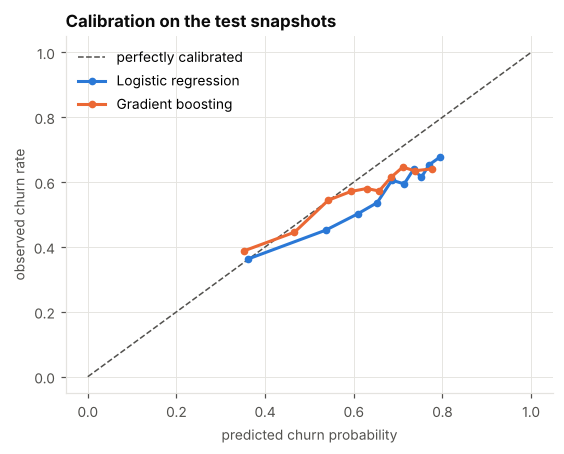

In [16]:
fig, ax = plt.subplots(figsize=(5.2, 4.2))
ax.plot([0, 1], [0, 1], color=MUTED, lw=1, ls="--", label="perfectly calibrated")
for color, name in zip(SERIES, ["Logistic regression", "Gradient boosting"]):
    frac, mean_pred = calibration_curve(y["test"], scores_test[name], n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac, color=color, marker="o", markersize=4, label=name)
ax.set_title("Calibration on the test snapshots"); ax.set_xlabel("predicted churn probability"); ax.set_ylabel("observed churn rate")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

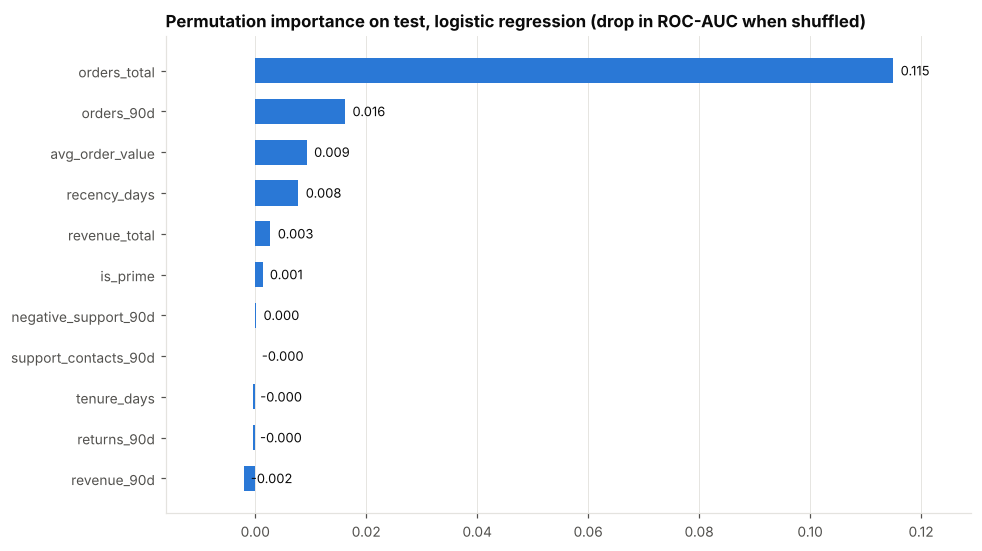

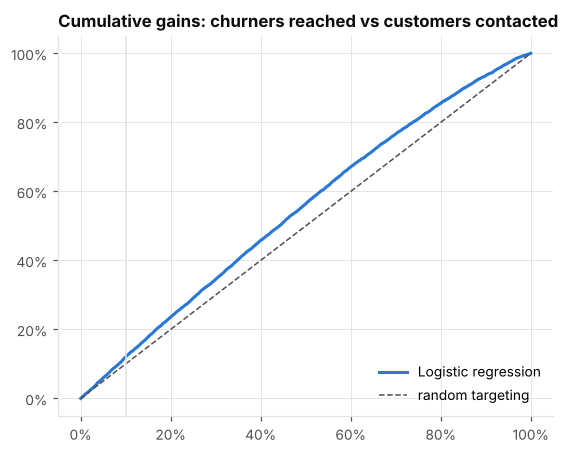

In [17]:
model = models[best_name]
imp = permutation_importance(model, X["test"], y["test"], scoring="roc_auc", n_repeats=10, random_state=0)
importance = pd.Series(imp.importances_mean, index=FEATURES)
hbar(importance, f"Permutation importance on test, {best_name.lower()} (drop in ROC-AUC when shuffled)", fmt="{:.3f}", color=SERIES[0])

order = np.argsort(-scores_test[best_name])
captured = np.cumsum(y["test"][order]) / y["test"].sum()
share = np.arange(1, len(order) + 1) / len(order)
fig, ax = plt.subplots(figsize=(5.2, 4.2))
ax.plot(share, captured, color=SERIES[0], label=best_name)
ax.plot([0, 1], [0, 1], color=MUTED, lw=1, ls="--", label="random targeting")
ax.axvline(0.1, color=GRID, lw=1)
ax.xaxis.set_major_formatter(PercentFormatter(1.0)); ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_title("Cumulative gains: churners reached vs customers contacted"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()
top10_capture = float(captured[int(0.1 * len(order)) - 1])
SUMMARY["churn"]["top_decile_capture"] = top10_capture
SUMMARY["churn"]["top_features"] = importance.sort_values(ascending=False).head(3).index.tolist()

In [18]:
c = SUMMARY["churn"]
print(f"{c['model']}: targeting the top 10% of customers by predicted risk catches {c['top_decile_capture']:.0%} of churners "
      f"at {c['top_decile_lift']:.1f}× the base rate ({c['top_decile_precision']:.0%} of those contacted churn vs {c['base_rate']:.0%} overall).")

Logistic regression: targeting the top 10% of customers by predicted risk catches 12% of churners at 1.2× the base rate (68% of those contacted churn vs 56% overall).


**Limitations.** The data is synthetic: churn emerges from the simulator's rules (purchase frequency fades after
45 days without an order, price-sensitive customers buy less after the February 2025 price change), and the strongest
signals that drive it (time since the last order, price sensitivity) are only partly visible in the features, so the
leakage-free model is weak; that weakness is the honest result. Real data would differ. `generators/gen_support.py` describes
NPS-driven churn, but it is not part of the default generation pipeline; support contacts here carry random sentiment,
which is why they add little. The stored `customer_monthly_features` table used to leak the snapshot month; that was
fixed and is now guarded by the validator.

## 11. Recommendation evaluation
Results from `python -m recommendations.evaluate`. For every order in the held-out final period, each method ranks
the same candidate list using only what was known an hour before the order. NDCG@10 rewards putting the products
the shopper actually bought near the top (1.0 = perfect, 0 = none in the top 10).

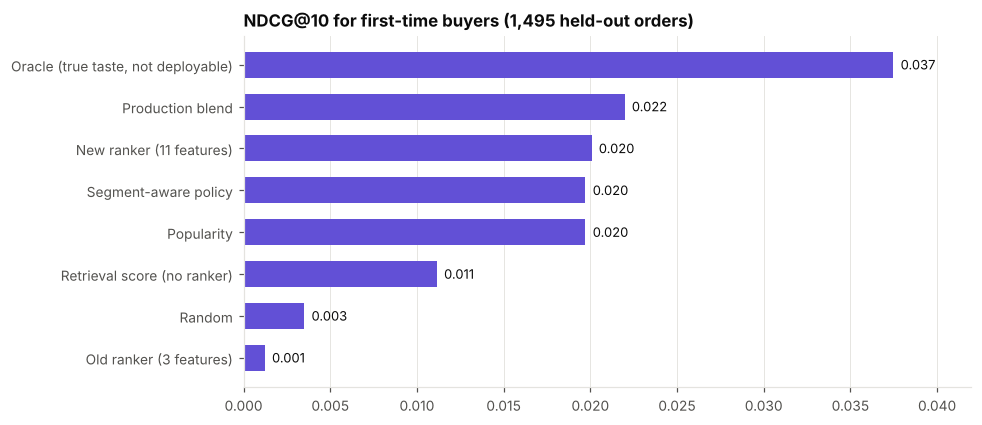

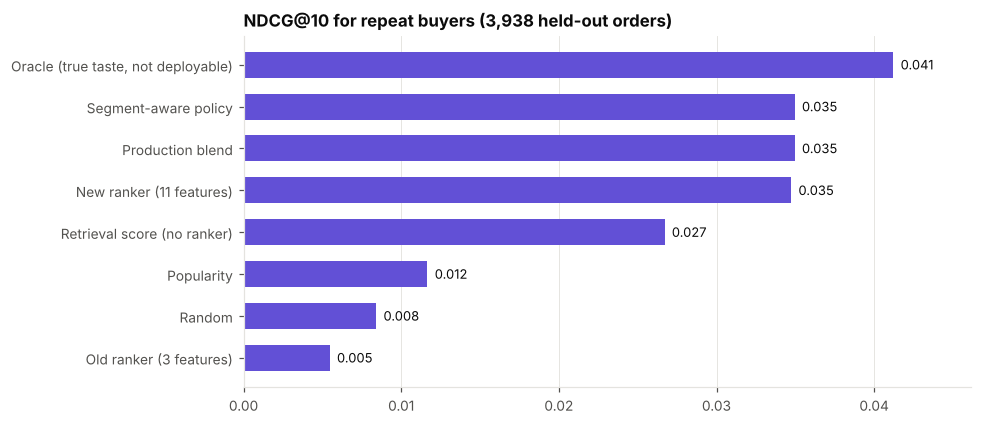

Candidate lists contained a bought product for 13.6% of test orders
new_ranker_vs_retrieval: +0.0083 (95% CI +0.0053 to +0.0111)
new_ranker_vs_popularity: +0.0168 (95% CI +0.0140 to +0.0197)
new_ranker_vs_legacy_ranker: +0.0264 (95% CI +0.0227 to +0.0303)
new_ranker_vs_random: +0.0236 (95% CI +0.0198 to +0.0275)
segment_aware_vs_retrieval: +0.0083 (95% CI +0.0059 to +0.0107)
segment_aware_vs_popularity: +0.0169 (95% CI +0.0143 to +0.0196)
segment_aware_vs_production_blend: -0.0006 (95% CI -0.0016 to +0.0003)


In [19]:
report_path = ROOT / "recommendations" / "reports" / "evaluation_report.json"
if report_path.exists():
    report = json.loads(report_path.read_text())
    names = {"random": "Random", "popularity": "Popularity", "retrieval": "Retrieval score (no ranker)",
             "legacy_ranker": "Old ranker (3 features)", "new_ranker": "New ranker (11 features)",
             "production_blend": "Production blend", "segment_aware": "Segment-aware policy",
             "oracle": "Oracle (true taste, not deployable)"}
    for group, label in [("first_order", "first-time buyers"), ("repeat_order", "repeat buyers")]:
        res = report["results"]["end_to_end"][group]
        ndcg = pd.Series({names[o]: m["@10"]["ndcg"] for o, m in res["orderings"].items() if m["@10"]})
        hbar(ndcg, f"NDCG@10 for {label} ({res['orders']:,} held-out orders)", fmt="{:.3f}", color=SERIES[6])
    r = report["retrieval"]
    print(f"Candidate lists contained a bought product for {r['pool_coverage']:.1%} of test orders")
    for name, c in report["comparisons_ndcg10"].items():
        print(f"{name}: {c['mean_diff']:+.4f} (95% CI {c['ci_low']:+.4f} to {c['ci_high']:+.4f})")
else:
    print("Run `python -m recommendations.evaluate` first.")

In [20]:
summary_path = ROOT / "analysis" / "insights_summary.json"
summary_path.write_text(json.dumps(SUMMARY, indent=2, default=float))
print(f"Wrote {summary_path.relative_to(ROOT)}")

Wrote analysis/insights_summary.json
